# 2. Your first substrate

`status: draft — executed end-to-end; download this page (top button) and run it as your scratchpad`

In this chapter you will **construct** a substrate, look inside it, and train it on XOR — a task no linear model can solve. Your first attempt will **fail at chance**, and the failure will teach you two things every trioron user needs: why initialisation scale matters in a substrate, and where the quad nonlinearity actually lives (per **dendritic branch**, not per cell).

**What you need:** the trioron repo on your path, torch, matplotlib. Everything runs on CPU in seconds.

## Step 1 — construct

A substrate is built from a **base** (a blueprint of cells and their wiring) compiled into an **arena** — flat tensors holding every cell's weights, bias, lock $\lambda$ and utility $u$. The workhorse base is `Seeded(input_dim, initial_classes, interior_cells, nonlinear)`: `input_dim` perception cells → `interior_cells` interior cells → `initial_classes` output cells, fully connected layer to layer.

Two parts of the recipe deserve formulas up front:

**Init scale.** The arena is born with edge weights of std $0.01$. Signals through two such layers shrink by $\sim 10^{-4}$ and cross-entropy sits at the $\ln 2$ plateau forever. The fix is fan-in scaling — resample each edge as

$$w_{ij} \sim \mathcal{N}\!\left(0, \tfrac{1}{\mathrm{fanin}(i)}\right)$$

so every cell's input variance is $O(1)$ regardless of how many edges feed it.

**Capacity.** `capacity` reserves arena slots for *future growth* — cells added later by division live in the same tensors. Always leave headroom.

In [1]:
import torch
from trioron.core import Envelope, construct
from trioron.bases.seeded import Seeded
from trioron.phenotype import default_dispatch_table

def make_substrate(in_dim, n_out, seed, nonlinear=True, interior=16):
    torch.manual_seed(seed)                      # fixes the initial WIRING, not just weights
    sub = construct(
        base=Seeded(in_dim, n_out, interior_cells=interior, nonlinear=nonlinear),
        envelope=Envelope(max_parameter_bytes=400_000),   # hard parameter budget
        dispatch_table=default_dispatch_table(),
        capacity=in_dim + interior + n_out + 8,           # cells now + headroom for growth
        sparsity_k=0)
    a = sub.arena                                # fan-in init (the formula above)
    with torch.no_grad():
        n = a.edge_cursor
        dst = a.edge_dst[:n]
        fan = torch.bincount(dst, minlength=a.edge_dst.numel()).float().clamp(min=1)
        a.edge_weight[:n] = torch.randn(n) / fan[dst].sqrt()
    sub.prepare_training()
    return sub

sub = make_substrate(2, 2, seed=0)
sub

Substrate(cells=20, edges=64, pressure=0.00)

## Step 2 — look inside

The arena is not a stack of `nn.Linear` layers: it is one cell population.

In [2]:
a = sub.arena
n_params = sum(t.numel() for t in sub.trainable_tensors())
print(f"cells: {a.bias.numel()}  edges: {a.edge_cursor}  trainable parameters: {n_params}")
print(f"lambda (epigenetic lock) per cell, first 8: {a.node_lambda[:8].tolist()}")

cells: 28  edges: 64  trainable parameters: 1932
lambda (epigenetic lock) per cell, first 8: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


Every cell already carries its $\lambda$ — all plastic (zero) at birth; chapter 4 raises it.

## Step 3 — a task that needs the nonlinearity

XOR blobs: four Gaussian clusters, opposite corners share a class. No linear map separates them, so this is the smallest honest test that nonlinearity is real.

In [3]:
def xor_data(n, seed):
    g = torch.Generator().manual_seed(seed)
    centers = torch.tensor([[-1.,-1.],[1.,1.],[-1.,1.],[1.,-1.]])
    labels  = torch.tensor([0,0,1,1])
    idx = torch.randint(0, 4, (n,), generator=g)
    X = centers[idx] + 0.15 * torch.randn(n, 2, generator=g)
    return X, labels[idx]

X, y = xor_data(2000, 0)
Xt, yt = xor_data(1000, 1)

## Step 4 — train (and fail)

The loop is plain torch: cross-entropy over the substrate's class-cell outputs, Adam at $3\times 10^{-3}$, and **gradient clipping at norm 1** — the quad activation can spike gradients, so clipping is part of the standard recipe, not a nicety.

In [4]:
import torch.nn.functional as F

def train(sub, X, y, epochs=40, lr=3e-3, bs=128, seed=0):
    params = sub.trainable_tensors()
    for p in params: p.requires_grad_(True)
    opt = torch.optim.Adam(params, lr=lr)
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        for bi in torch.randperm(len(y), generator=g).split(bs):
            opt.zero_grad()
            F.cross_entropy(sub(X[bi]), y[bi]).backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            opt.step()
    for p in params: p.requires_grad_(False)
    return sub

@torch.no_grad()
def accuracy(sub, X, y):
    return (sub(X).argmax(1) == y).float().mean().item()

train(sub, X, y)
print(f"2-d input, quad substrate: {accuracy(sub, Xt, yt):.3f}   (chance = 0.5)")

2-d input, quad substrate: 0.455   (chance = 0.5)


**Chance.** Not a bug in your loop — a lesson in where the quad lives.

## Step 5 — the quad is per *branch*, not per cell

In a `Seeded(nonlinear=True)` substrate each interior cell's fan-in is split into **two dendritic branches**, and the quad applies to each branch's sum:

$$h_i \;=\; \sum_{k=1}^{K} \sigma\!\Big(\sum_{j \in B_k} w_{ij} x_j\Big), \qquad \sigma(z) = z + z^2 .$$

Expand $\sigma$ of a branch sum and you get the **products of inputs that share a branch**: $\big(\sum_j w_j x_j\big)^2$ contains every cross-term $2\,w_a w_b\, x_a x_b$ with $a, b \in B_k$. XOR *is* a cross-term — its label is the sign of $x_1 x_2$.

With `input_dim=2` and two branches, each branch holds **one** edge: $\sigma(w x) = wx + w^2x^2$ gives only $x_1^2$ and $x_2^2$ — and in the basis $(x_1, x_2, x_1^2, x_2^2)$ the XOR classes are indistinguishable. The substrate was not too weak; the two inputs **never met in a branch**.

The fix costs nothing: present the input so that both coordinates land in every branch — duplicate it, $[x_1, x_2] \to [x_1, x_2, x_1, x_2]$. Now each branch holds a full copy and the cross-term exists.

In [5]:
X4, Xt4 = torch.cat([X, X], 1), torch.cat([Xt, Xt], 1)
quad = train(make_substrate(4, 2, seed=0), X4, y)
print(f"duplicated input, quad substrate: {accuracy(quad, Xt4, yt):.3f}")

duplicated input, quad substrate: 1.000


## Step 6 — the control: same everything, linear

`nonlinear=False`, same duplicated input, same budget. A deep **linear** network is one linear map whatever its depth — if our story is honest, this must fail.

In [6]:
lin = train(make_substrate(4, 2, seed=0, nonlinear=False), X4, y)
print(f"duplicated input, linear substrate: {accuracy(lin, Xt4, yt):.3f}   (chance = 0.5)")

duplicated input, linear substrate: 0.560   (chance = 0.5)


## Step 7 — see it

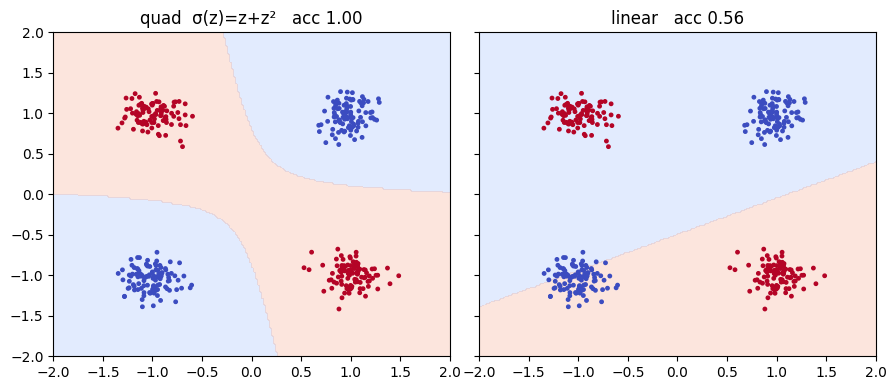

In [7]:
import matplotlib.pyplot as plt

gx = torch.linspace(-2, 2, 200)
G2 = torch.cartesian_prod(gx, gx)
G4 = torch.cat([G2, G2], 1)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, s, title in [(axes[0], quad, "quad  σ(z)=z+z²"), (axes[1], lin, "linear")]:
    with torch.no_grad():
        Z = s(G4).argmax(1).reshape(200, 200)
    ax.contourf(gx, gx, Z.T, levels=1, cmap="coolwarm", alpha=0.25)
    ax.scatter(Xt[:400,0], Xt[:400,1], c=yt[:400], cmap="coolwarm", s=6)
    ax.set_title(f"{title}   acc {accuracy(s, torch.cat([Xt,Xt],1), yt):.2f}")
plt.tight_layout()
plt.show()

## What you learned
1. `construct(Seeded(...), capacity=...)` compiles a blueprint into an **arena** — one cell population carrying $w, \lambda, u$ per cell, with headroom for growth.
2. **Fan-in init** ($w \sim \mathcal{N}(0, 1/\mathrm{fanin})$) is mandatory: the arena's native std-0.01 init parks two-layer substrates on the $\ln 2$ plateau.
3. The quad nonlinearity acts **per dendritic branch**; interactions exist only between inputs that share a branch. Tiny inputs need duplication (or a base whose branching puts interacting features together).
4. Train with plain torch + **grad-clip 1.0**; freeze (`requires_grad_(False)`) when done.

**Tips**
- Seed **before** `construct` — the seed fixes the initial wiring, and reproducibility of *structure* matters as much as of weights.
- `Envelope(max_parameter_bytes=...)` is a hard budget; construction that would exceed it fails loudly. Budget first, architecture second.
- If loss sits at exactly $\ln 2 \approx 0.693$, suspect **signal scale** (init) or **missing cross-terms** (branching) before suspecting capacity.

*Next:* [Growth](03-growth.md) — what happens when a substrate meets a task it cannot fit.